## Temperature Distribution

The distribution of temperature values is visualized using a histogram.

This helps understand the range, concentration, and overall distribution of
temperature observations in the dataset.

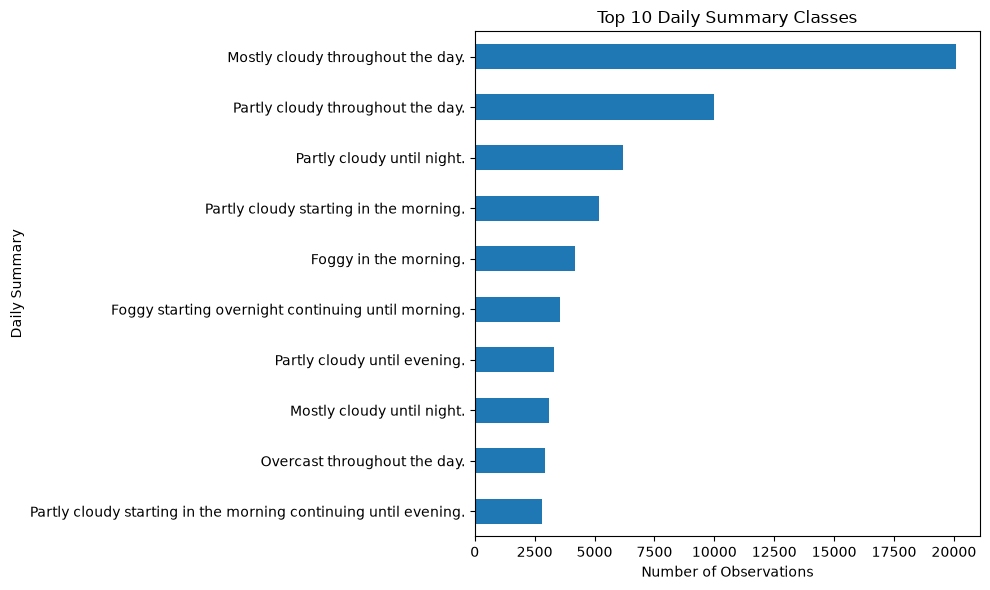

In [26]:
plt.figure(figsize=(10, 6))

top_classes.sort_values().plot(kind="barh")

plt.xlabel("Number of Observations")
plt.ylabel("Daily Summary")
plt.title("Top 10 Daily Summary Classes")

plt.tight_layout()
plt.show()

## Temperature vs Humidity

A scatter plot is used to examine the relationship between temperature and
humidity.

This visualization helps identify whether changes in humidity are associated
with changes in temperature.

## Temperature vs Wind Speed

A scatter plot is used to examine the relationship between temperature and
wind speed.

This helps understand whether temperature shows any noticeable relationship
with wind speed.

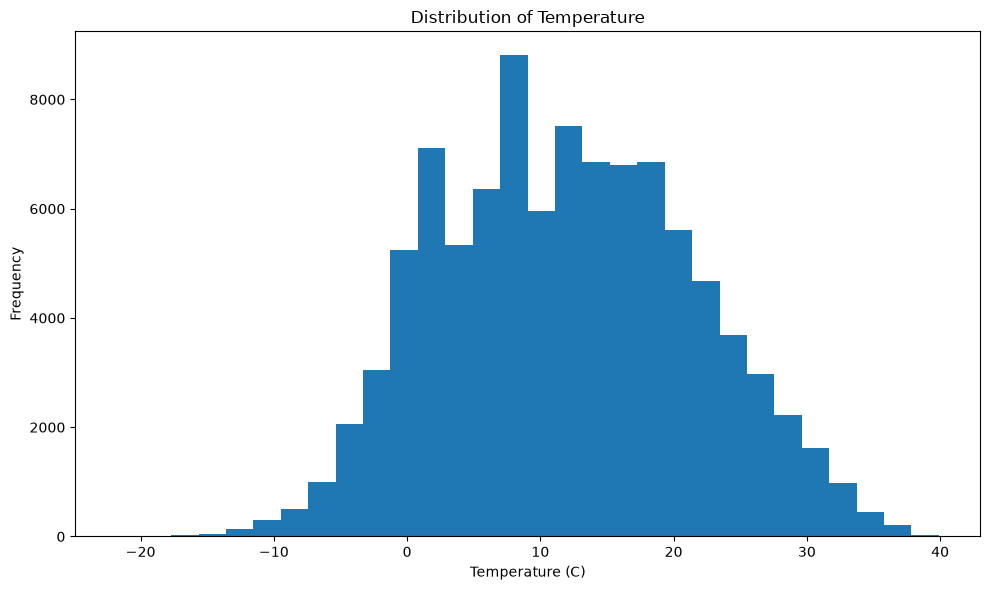

In [27]:
plt.figure(figsize=(10, 6))

plt.hist(df["Temperature (C)"], bins=30)

plt.xlabel("Temperature (C)")
plt.ylabel("Frequency")
plt.title("Distribution of Temperature")

plt.tight_layout()
plt.show()

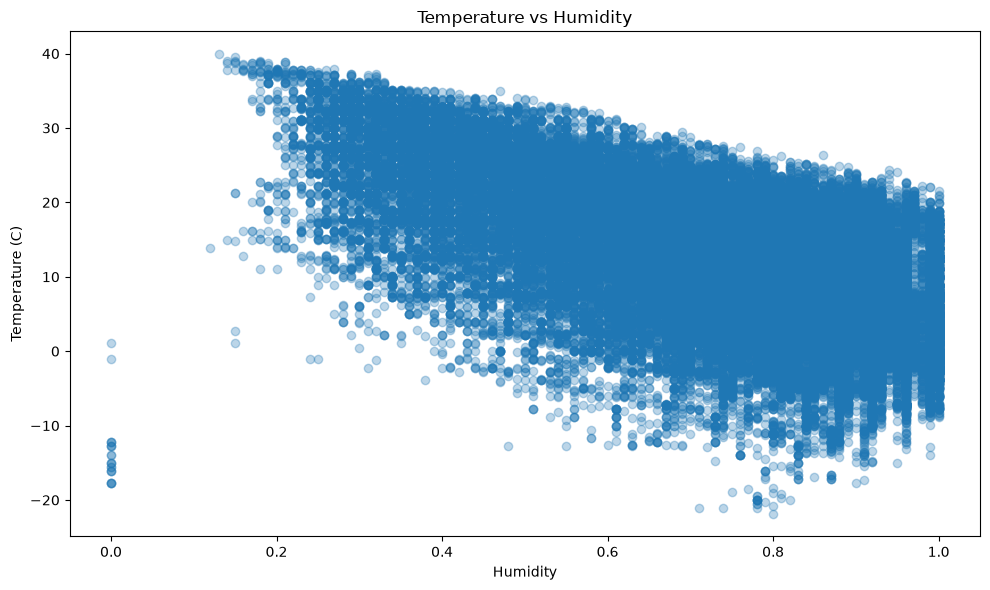

In [28]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Humidity"],
    df["Temperature (C)"],
    alpha=0.3
)

plt.xlabel("Humidity")
plt.ylabel("Temperature (C)")
plt.title("Temperature vs Humidity")

plt.tight_layout()
plt.show()

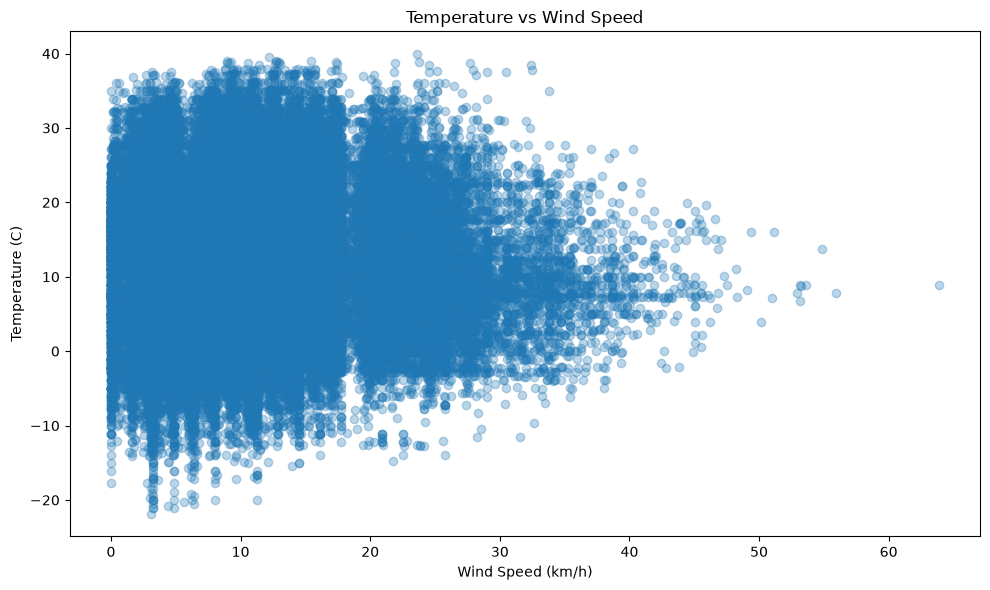

In [29]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Wind Speed (km/h)"],
    df["Temperature (C)"],
    alpha=0.3
)

plt.xlabel("Wind Speed (km/h)")
plt.ylabel("Temperature (C)")
plt.title("Temperature vs Wind Speed")

plt.tight_layout()
plt.show()

## Correlation Heatmap

A correlation matrix is calculated for the numerical weather variables.

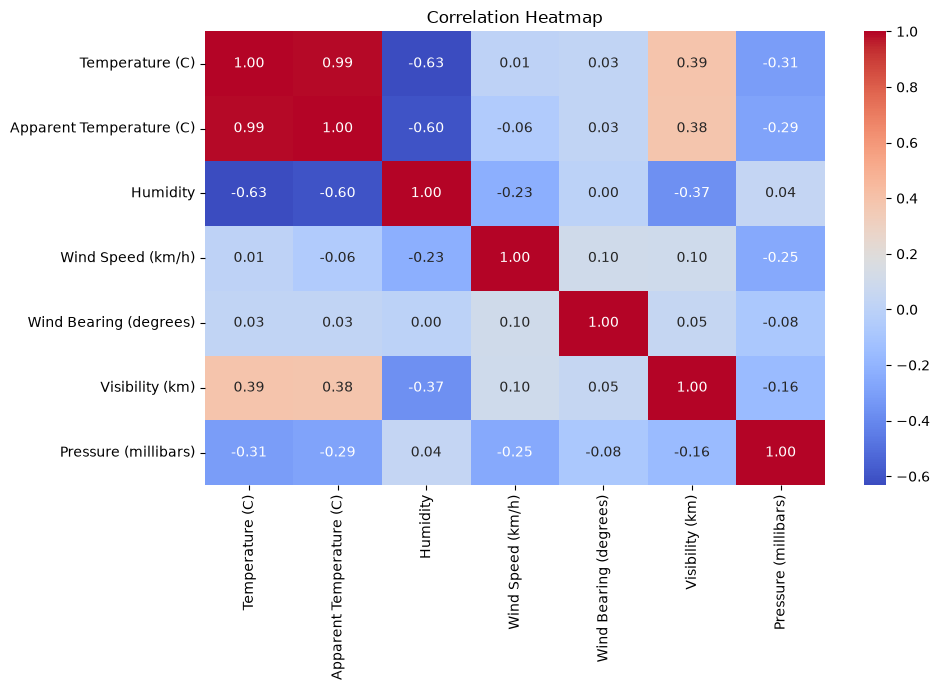

In [30]:
correlation = df.select_dtypes(include="number").corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## EDA Finding: Correlation Analysis

The correlation heatmap shows the relationships between the numerical weather
features.

Temperature and Apparent Temperature have a very strong positive correlation
of 0.99, indicating that both variables contain highly similar information.

Temperature has a moderate negative correlation with Humidity (-0.63), while
Apparent Temperature has a moderate negative correlation with Humidity (-0.60).

Temperature has a moderate positive correlation with Visibility (0.39) and
a weak-to-moderate negative correlation with Pressure (-0.31).

Wind Bearing shows very weak linear relationships with most of the other
features.

The correlation analysis provides useful information for understanding
feature relationships before model development.

## 12. Feature Engineering – Date and Time

The `Formatted Date` column contains both date and time information.

To make this information useful for machine learning models, the date is
converted into a datetime format and separate features are extracted:

- Year
- Month
- Day
- Hour
- DayOfWeek

These features can capture seasonal, monthly, daily, and weekly patterns
that may help predict the `Daily Summary` class.

In [31]:
df["Formatted Date"] = pd.to_datetime(
    df["Formatted Date"],
    utc=True
)

In [32]:
df["Year"] = df["Formatted Date"].dt.year
df["Month"] = df["Formatted Date"].dt.month
df["Day"] = df["Formatted Date"].dt.day
df["Hour"] = df["Formatted Date"].dt.hour
df["DayOfWeek"] = df["Formatted Date"].dt.dayofweek

In [33]:
df[
    [
        "Formatted Date",
        "Year",
        "Month",
        "Day",
        "Hour",
        "DayOfWeek"
    ]
].head()

,Formatted Date,Year,Month,Day,Hour,DayOfWeek
0,2006-03-31 22:00:00+00:00,2006,3,31,22,4
1,2006-03-31 23:00:00+00:00,2006,3,31,23,4
2,2006-04-01 00:00:00+00:00,2006,4,1,0,5
3,2006-04-01 01:00:00+00:00,2006,4,1,1,5
4,2006-04-01 02:00:00+00:00,2006,4,1,2,5


## 13. Encoding Categorical Features

Machine learning algorithms require numerical input features.

The `Summary` and `Precip Type` columns are categorical variables, so they
must be converted into numerical representations.

One-hot encoding is used for the categorical input features. This creates
binary columns for each category and avoids assigning an artificial numerical
ordering to the categories.

The target variable `Daily Summary` is encoded separately using LabelEncoder
because it contains 214 different classes.

In [34]:
df = pd.get_dummies(
    df,
    columns=["Summary", "Precip Type"],
    drop_first=False,
    dtype=int
)

print("Shape after categorical encoding:", df.shape)

Shape after categorical encoding: (96429, 43)


In [35]:
print(df.columns.tolist())

['Formatted Date', 'Temperature (C)', 'Apparent Temperature (C)', 'Humidity', 'Wind Speed (km/h)', 'Wind Bearing (degrees)', 'Visibility (km)', 'Pressure (millibars)', 'Daily Summary', 'Year', 'Month', 'Day', 'Hour', 'DayOfWeek', 'Summary_Breezy', 'Summary_Breezy and Dry', 'Summary_Breezy and Foggy', 'Summary_Breezy and Mostly Cloudy', 'Summary_Breezy and Overcast', 'Summary_Breezy and Partly Cloudy', 'Summary_Clear', 'Summary_Dangerously Windy and Partly Cloudy', 'Summary_Drizzle', 'Summary_Dry', 'Summary_Dry and Mostly Cloudy', 'Summary_Dry and Partly Cloudy', 'Summary_Foggy', 'Summary_Humid and Mostly Cloudy', 'Summary_Humid and Overcast', 'Summary_Humid and Partly Cloudy', 'Summary_Light Rain', 'Summary_Mostly Cloudy', 'Summary_Overcast', 'Summary_Partly Cloudy', 'Summary_Rain', 'Summary_Windy', 'Summary_Windy and Dry', 'Summary_Windy and Foggy', 'Summary_Windy and Mostly Cloudy', 'Summary_Windy and Overcast', 'Summary_Windy and Partly Cloudy', 'Precip Type_rain', 'Precip Type_snow

## 14. Target Variable Encoding

The target variable is `Daily Summary`.

It contains 214 unique weather-summary categories. LabelEncoder is used to
convert each categorical class into a numerical label from 0 to 213.

The encoded labels are required because the classification algorithms work
with numerical target values.

In [36]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y = label_encoder.fit_transform(df["Daily Summary"])

print("Number of classes:", len(label_encoder.classes_))
print("First 10 encoded labels:", y[:10])

Number of classes: 214
First 10 encoded labels: [197 197 197 197 197 197 197 197 197 197]


In [37]:
X = df.drop(
    columns=["Daily Summary", "Formatted Date"]
)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (96429, 41)
y shape: (96429,)


## 15. Feature and Target Separation

The dataset is divided into input features (`X`) and the target variable
(`y`).

In [38]:
print(X.dtypes)

Temperature (C)                                float64
Apparent Temperature (C)                       float64
Humidity                                       float64
Wind Speed (km/h)                              float64
Wind Bearing (degrees)                         float64
Visibility (km)                                float64
Pressure (millibars)                           float64
Year                                             int32
Month                                            int32
Day                                              int32
Hour                                             int32
DayOfWeek                                        int32
Summary_Breezy                                   int64
Summary_Breezy and Dry                           int64
Summary_Breezy and Foggy                         int64
Summary_Breezy and Mostly Cloudy                 int64
Summary_Breezy and Overcast                      int64
Summary_Breezy and Partly Cloudy                 int64
Summary_Cl

In [39]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (96429, 41)
y shape: (96429,)


## 16. Train-Test Split

The dataset is divided into training and testing sets using an 80:20 ratio.


In [40]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (77143, 41)
X_test : (19286, 41)
y_train: (77143,)
y_test : (19286,)


## 17. Feature Scaling

Feature scaling is required for KNN because KNN calculates distances between
observations.

StandardScaler transforms the numerical features so that they have a
comparable scale.


In [41]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled X_train shape:", X_train_scaled.shape)
print("Scaled X_test shape :", X_test_scaled.shape)

Scaled X_train shape: (77143, 41)
Scaled X_test shape : (19286, 41)


## 18. K-Nearest Neighbors (KNN) Classifier

K-Nearest Neighbors (KNN) classifies a new observation based on the classes
of its nearest neighboring observations.

Since KNN relies on distance calculations, the standardized features created
in the previous step are used.

In [42]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_scaled, y_train)



,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](214,)","[ 0, 1, 2,...,211,212,213]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [43]:
y_pred_knn = knn_model.predict(X_test_scaled)

print("Actual labels:")
print(y_test[:10])

print("\nPredicted labels:")
print(y_pred_knn[:10])

Actual labels:
[170 197 197 111  43 111 111 197  41 188]

Predicted labels:
[170 197 197 111  43 111 111 197 209 187]


In [44]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy_knn = accuracy_score(y_test, y_pred_knn)

precision_knn = precision_score(
    y_test,
    y_pred_knn,
    average="weighted",
    zero_division=0
)

recall_knn = recall_score(
    y_test,
    y_pred_knn,
    average="weighted",
    zero_division=0
)

f1_knn = f1_score(
    y_test,
    y_pred_knn,
    average="weighted",
    zero_division=0
)

print("KNN Classification Results")
print("--------------------------")
print("Accuracy :", accuracy_knn)
print("Precision:", precision_knn)
print("Recall   :", recall_knn)
print("F1 Score :", f1_knn)

KNN Classification Results
--------------------------
Accuracy : 0.6171315980503993
Precision: 0.6173007892040795
Recall   : 0.6171315980503993
F1 Score : 0.6119257669143776


## KNN Model Evaluation

The KNN classifier is evaluated using Accuracy, Weighted Precision, Weighted
Recall, and Weighted F1-score.

## 19. Decision Tree Classifier

A Decision Tree Classifier is developed as the second machine learning model.

A decision tree recursively divides the feature space using decision rules
and assigns a class to each observation.

Unlike KNN, Decision Trees do not require feature scaling. Therefore, the
original numerical feature values are used for training and prediction.

In [45]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    random_state=42
)

dt_model.fit(X_train, y_train)



,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [46]:
y_pred_dt = dt_model.predict(X_test)

print("Actual labels:")
print(y_test[:10])

print("\nPredicted labels:")
print(y_pred_dt[:10])

Actual labels:
[170 197 197 111  43 111 111 197  41 188]

Predicted labels:
[170 197 197 111  43 111 111 197 111 188]


In [47]:
accuracy_dt = accuracy_score(y_test, y_pred_dt)

precision_dt = precision_score(
    y_test,
    y_pred_dt,
    average="weighted",
    zero_division=0
)

recall_dt = recall_score(
    y_test,
    y_pred_dt,
    average="weighted",
    zero_division=0
)

f1_dt = f1_score(
    y_test,
    y_pred_dt,
    average="weighted",
    zero_division=0
)

print("Decision Tree Classification Results")
print("------------------------------------")
print("Accuracy :", accuracy_dt)
print("Precision:", precision_dt)
print("Recall   :", recall_dt)
print("F1 Score :", f1_dt)

Decision Tree Classification Results
------------------------------------
Accuracy : 0.6574198900757026
Precision: 0.6599314949306694
Recall   : 0.6574198900757026
F1 Score : 0.6573516894672224


## Decision Tree Evaluation

The Decision Tree Classifier is evaluated using accuracy, weighted precision,
weighted recall, and weighted F1-score.

These metrics are calculated on the unseen test dataset. The results will be
compared with the KNN classifier to determine which model performs better for
the multiclass Daily Summary prediction task.

## 20. Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines multiple
Decision Trees to produce a more robust classification model.

Random Forest is selected as the third model because it can capture complex
relationships between weather features and is generally more robust than a
single Decision Tree.

Feature scaling is not required for Random Forest, so the original feature
values are used.


In [48]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=1
)

print("Random Forest model created successfully.")

Random Forest model created successfully.


In [49]:
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [50]:
y_pred_rf = rf_model.predict(X_test)

print("Actual labels:")
print(y_test[:10])

print("\nPredicted labels:")
print(y_pred_rf[:10])

Actual labels:
[170 197 197 111  43 111 111 197  41 188]

Predicted labels:
[209 197 197 111  43 111 111 197  41 188]


In [51]:
accuracy_rf = accuracy_score(y_test, y_pred_rf)

precision_rf = precision_score(
    y_test,
    y_pred_rf,
    average="weighted",
    zero_division=0
)

recall_rf = recall_score(
    y_test,
    y_pred_rf,
    average="weighted",
    zero_division=0
)

f1_rf = f1_score(
    y_test,
    y_pred_rf,
    average="weighted",
    zero_division=0
)

print("Random Forest Classification Results")
print("------------------------------------")
print("Accuracy :", accuracy_rf)
print("Precision:", precision_rf)
print("Recall   :", recall_rf)
print("F1 Score :", f1_rf)

Random Forest Classification Results
------------------------------------
Accuracy : 0.7764181271388572
Precision: 0.7947248384467331
Recall   : 0.7764181271388572
F1 Score : 0.7741882926621176


## Random Forest Evaluation

The Random Forest model is evaluated using accuracy, weighted precision,
weighted recall, and weighted F1-score.

The results are compared with KNN and Decision Tree using the same unseen test
dataset.

The model with the strongest overall evaluation performance will be selected
for further validation, hyperparameter tuning, and final prediction.

In [52]:
results = pd.DataFrame({
    "Model": [
        "KNN Classifier",
        "Decision Tree Classifier",
        "Random Forest Classifier"
    ],
    "Accuracy": [
        accuracy_knn,
        accuracy_dt,
        accuracy_rf
    ],
    "Precision": [
        precision_knn,
        precision_dt,
        precision_rf
    ],
    "Recall": [
        recall_knn,
        recall_dt,
        recall_rf
    ],
    "F1 Score": [
        f1_knn,
        f1_dt,
        f1_rf
    ]
})

results

,Model,Accuracy,Precision,Recall,F1 Score
0,KNN Classifier,0.617132,0.617301,0.617132,0.611926
1,Decision Tree Classifier,0.657420,0.659931,0.657420,0.657352
2,Random Forest Classifier,0.776418,0.794725,0.776418,0.774188


In [53]:
results_display = results.copy()

for column in ["Accuracy", "Precision", "Recall", "F1 Score"]:
    results_display[column] = (
        results_display[column] * 100
    ).round(2)

results_display

,Model,Accuracy,Precision,Recall,F1 Score
0,KNN Classifier,61.71,61.73,61.71,61.19
1,Decision Tree Classifier,65.74,65.99,65.74,65.74
2,Random Forest Classifier,77.64,79.47,77.64,77.42


## Model Comparison

Three machine learning classification algorithms were developed and
evaluated: KNN, Decision Tree, and Random Forest.

In [54]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

rf_cv = RandomForestClassifier(
    n_estimators=50,
    random_state=42,
    n_jobs=1
)

skf = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    rf_cv,
    X_train,
    y_train,
    cv=skf,
    scoring="accuracy",
    n_jobs=1
)

print("Cross-Validation Accuracy:", cv_scores)
print("Mean CV Accuracy:", cv_scores.mean())

Cross-Validation Accuracy: [0.6941085  0.6806409  0.69506883]
Mean CV Accuracy: 0.6899394090314357


## Model Validation – Random Forest

Three-fold stratified cross-validation is performed to assess the stability
of the Random Forest classifier.

In [55]:
from sklearn.model_selection import RandomizedSearchCV

In [56]:
param_grid = {
    "n_estimators": [50, 100],
    "max_depth": [10, 20, None],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt", 1.0]
}

In [57]:
rf_tuning = RandomizedSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ),
    param_distributions=param_grid,
    n_iter=5,
    cv=3,
    scoring="accuracy",
    random_state=42,
    n_jobs=1
)

In [59]:
rf_tuning.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [10, 20, ...], 'max_features': ['sqrt', 1.0], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple 

## Hyperparameter Tuning – Random Forest

Hyperparameter tuning is performed on the Random Forest classifier to
determine whether a better configuration can improve its classification
performance.

RandomizedSearchCV is used to explore different combinations of important
hyperparameters, including the number of trees, maximum tree depth, minimum
samples required for splitting, minimum samples per leaf, and the number of
features considered at each split.

A small randomized search with three-fold cross-validation is used because
the dataset is large and contains 214 target classes. This reduces
computational requirements while still allowing several configurations to
be evaluated.

The best parameter configuration will later be evaluated on the unseen test
set and compared with the baseline Random Forest.

In [61]:
y_pred_rf_tuned = rf_tuning.best_estimator_.predict(X_test)

accuracy_rf_tuned = accuracy_score(y_test, y_pred_rf_tuned)

precision_rf_tuned = precision_score(
    y_test,
    y_pred_rf_tuned,
    average="weighted",
    zero_division=0
)

recall_rf_tuned = recall_score(
    y_test,
    y_pred_rf_tuned,
    average="weighted",
    zero_division=0
)

f1_rf_tuned = f1_score(
    y_test,
    y_pred_rf_tuned,
    average="weighted",
    zero_division=0
)

print("Tuned Random Forest Classification Results")
print("-------------------------------------------")
print("Accuracy :", accuracy_rf_tuned)
print("Precision:", precision_rf_tuned)
print("Recall   :", recall_rf_tuned)
print("F1 Score :", f1_rf_tuned)

Tuned Random Forest Classification Results
-------------------------------------------
Accuracy : 0.823135953541429
Precision: 0.8281552435181991
Recall   : 0.823135953541429
F1 Score : 0.8214245623365971


## Tuned Random Forest Evaluation

The tuned Random Forest was evaluated on the unseen test dataset and achieved
an accuracy of 82.31%, weighted precision of 82.82%, weighted recall of
82.31%, and weighted F1-score of 82.14%.

In [63]:
final_comparison = pd.DataFrame({
    "Model": [
        "KNN Classifier",
        "Decision Tree Classifier",
        "Random Forest",
        "Tuned Random Forest"
    ],
    "Accuracy": [
        accuracy_knn,
        accuracy_dt,
        accuracy_rf,
        accuracy_rf_tuned
    ],
    "Precision": [
        precision_knn,
        precision_dt,
        precision_rf,
        precision_rf_tuned
    ],
    "Recall": [
        recall_knn,
        recall_dt,
        recall_rf,
        recall_rf_tuned
    ],
    "F1 Score": [
        f1_knn,
        f1_dt,
        f1_rf,
        f1_rf_tuned
    ]
})

final_comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,KNN Classifier,0.617132,0.617301,0.617132,0.611926
1,Decision Tree Classifier,0.657420,0.659931,0.657420,0.657352
2,Random Forest,0.776418,0.794725,0.776418,0.774188
3,Tuned Random Forest,0.823136,0.828155,0.823136,0.821425


In [65]:
import os

model_path = "../models/random_forest_tuned.pkl"

print("File exists:", os.path.exists(model_path))

if os.path.exists(model_path):
    print("File size:", os.path.getsize(model_path), "bytes")

File exists: True
File size: 0 bytes


In [66]:
rf_tuning.best_estimator_

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",50
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total numb

In [67]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(
    rf_tuning.best_estimator_,
    "../models/random_forest_tuned.pkl"
)

print("Random Forest model saved successfully.")

Random Forest model saved successfully.


In [68]:
joblib.dump(
    label_encoder,
    "../models/label_encoder.pkl"
)

print("Label encoder saved successfully.")

Label encoder saved successfully.


In [70]:
print(
    "Random Forest:",
    os.path.getsize("../models/random_forest_tuned.pkl"),
    "bytes"
)

print(
    "Label Encoder:",
    os.path.getsize("../models/label_encoder.pkl"),
    "bytes"
)

Random Forest: 3253012937 bytes
Label Encoder: 14571 bytes


In [71]:
final_model = joblib.load(
    "../models/random_forest_tuned.pkl"
)

final_encoder = joblib.load(
    "../models/label_encoder.pkl"
)

print("Final model loaded successfully.")
print("Label encoder loaded successfully.")

Final model loaded successfully.
Label encoder loaded successfully.


In [72]:
final_model = rf_tuning.best_estimator_

print("Final model:", type(final_model).__name__)
print("Number of trees:", final_model.n_estimators)
print("Number of features:", final_model.n_features_in_)

Final model: RandomForestClassifier
Number of trees: 50
Number of features: 41


In [73]:
print(X.columns.tolist())

['Temperature (C)', 'Apparent Temperature (C)', 'Humidity', 'Wind Speed (km/h)', 'Wind Bearing (degrees)', 'Visibility (km)', 'Pressure (millibars)', 'Year', 'Month', 'Day', 'Hour', 'DayOfWeek', 'Summary_Breezy', 'Summary_Breezy and Dry', 'Summary_Breezy and Foggy', 'Summary_Breezy and Mostly Cloudy', 'Summary_Breezy and Overcast', 'Summary_Breezy and Partly Cloudy', 'Summary_Clear', 'Summary_Dangerously Windy and Partly Cloudy', 'Summary_Drizzle', 'Summary_Dry', 'Summary_Dry and Mostly Cloudy', 'Summary_Dry and Partly Cloudy', 'Summary_Foggy', 'Summary_Humid and Mostly Cloudy', 'Summary_Humid and Overcast', 'Summary_Humid and Partly Cloudy', 'Summary_Light Rain', 'Summary_Mostly Cloudy', 'Summary_Overcast', 'Summary_Partly Cloudy', 'Summary_Rain', 'Summary_Windy', 'Summary_Windy and Dry', 'Summary_Windy and Foggy', 'Summary_Windy and Mostly Cloudy', 'Summary_Windy and Overcast', 'Summary_Windy and Partly Cloudy', 'Precip Type_rain', 'Precip Type_snow']


## 31. Sample / Unseen Data Prediction

The final tuned Random Forest model is used to predict the `Daily Summary`
for a new, unseen weather observation.


In [74]:
new_data = pd.DataFrame(
    0,
    index=[0],
    columns=X.columns
)

new_data["Temperature (C)"] = 15.0
new_data["Apparent Temperature (C)"] = 15.0
new_data["Humidity"] = 0.75
new_data["Wind Speed (km/h)"] = 10.0
new_data["Wind Bearing (degrees)"] = 180.0
new_data["Visibility (km)"] = 10.0
new_data["Pressure (millibars)"] = 1016.55

new_data["Year"] = 2006
new_data["Month"] = 4
new_data["Day"] = 1
new_data["Hour"] = 12
new_data["DayOfWeek"] = 5

new_data["Summary_Partly Cloudy"] = 1

new_data["Precip Type_rain"] = 1
new_data["Precip Type_snow"] = 0

print("Unseen data created successfully.")
print(new_data)

Unseen data created successfully.
   Temperature (C)  Apparent Temperature (C)  Humidity  Wind Speed (km/h)  \
0             15.0                      15.0      0.75               10.0   

   Wind Bearing (degrees)  Visibility (km)  Pressure (millibars)  Year  Month  \
0                   180.0             10.0               1016.55  2006      4   

   Day  ...  Summary_Partly Cloudy  Summary_Rain  Summary_Windy  \
0    1  ...                      1             0              0   

   Summary_Windy and Dry  Summary_Windy and Foggy  \
0                      0                        0   

   Summary_Windy and Mostly Cloudy  Summary_Windy and Overcast  \
0                                0                           0   

   Summary_Windy and Partly Cloudy  Precip Type_rain  Precip Type_snow  
0                                0                 1                 0  

[1 rows x 41 columns]


In [76]:
predicted_label = final_model.predict(new_data)[0]

print("Predicted encoded label:", predicted_label)

Predicted encoded label: 197


In [77]:
predicted_summary = label_encoder.inverse_transform(
    [predicted_label]
)[0]

print("Predicted Daily Summary:", predicted_summary)

Predicted Daily Summary: Partly cloudy throughout the day.


In [ ]:
final_model = rf_tuning.best_estimator_

In [81]:
predicted_label = final_model.predict(new_data)[0]

print("Predicted encoded label:", predicted_label)

Predicted encoded label: 197


In [82]:
predicted_summary = label_encoder.inverse_transform(
    [predicted_label]
)[0]

print("Predicted Daily Summary:", predicted_summary)

Predicted Daily Summary: Partly cloudy throughout the day.


In [83]:
print("==========================================")
print("       WEATHER DAILY SUMMARY PREDICTION")
print("==========================================")

print("Temperature          :", new_data["Temperature (C)"].iloc[0], "°C")
print("Apparent Temperature :", new_data["Apparent Temperature (C)"].iloc[0], "°C")
print("Humidity             :", new_data["Humidity"].iloc[0])
print("Wind Speed           :", new_data["Wind Speed (km/h)"].iloc[0], "km/h")
print("Wind Bearing         :", new_data["Wind Bearing (degrees)"].iloc[0], "degrees")
print("Visibility           :", new_data["Visibility (km)"].iloc[0], "km")
print("Pressure             :", new_data["Pressure (millibars)"].iloc[0], "millibars")
print("Summary              : Partly Cloudy")
print("Precipitation Type   : Rain")

print("------------------------------------------")
print("Predicted Daily Summary:")
print(predicted_summary)
print("==========================================")

       WEATHER DAILY SUMMARY PREDICTION
Temperature          : 15.0 °C
Apparent Temperature : 15.0 °C
Humidity             : 0.75
Wind Speed           : 10.0 km/h
Wind Bearing         : 180.0 degrees
Visibility           : 10.0 km
Pressure             : 1016.55 millibars
Summary              : Partly Cloudy
Precipitation Type   : Rain
------------------------------------------
Predicted Daily Summary:
Partly cloudy throughout the day.


In [84]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_rf_tuned)

print("Confusion Matrix Shape:", cm.shape)

Confusion Matrix Shape: (214, 214)


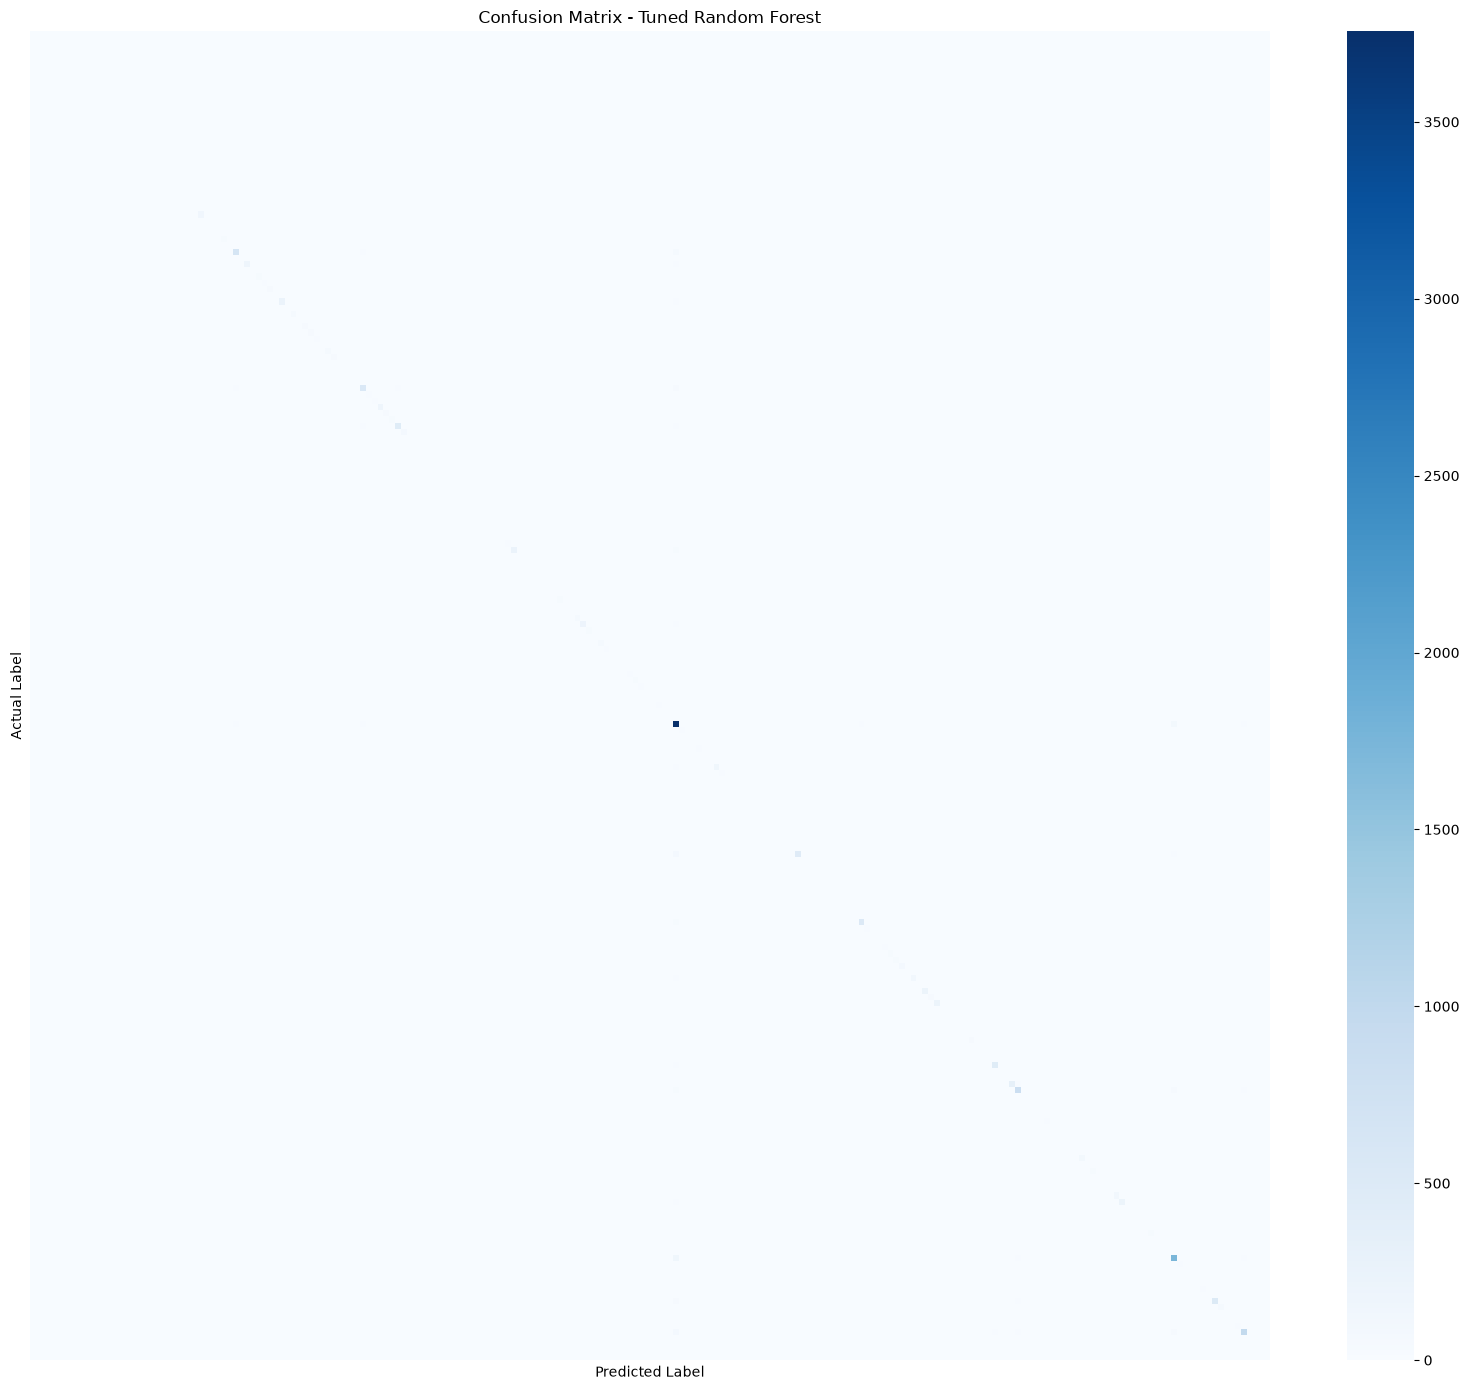

In [85]:
plt.figure(figsize=(16, 14))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=False,
    yticklabels=False
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Tuned Random Forest")

plt.tight_layout()
plt.show()

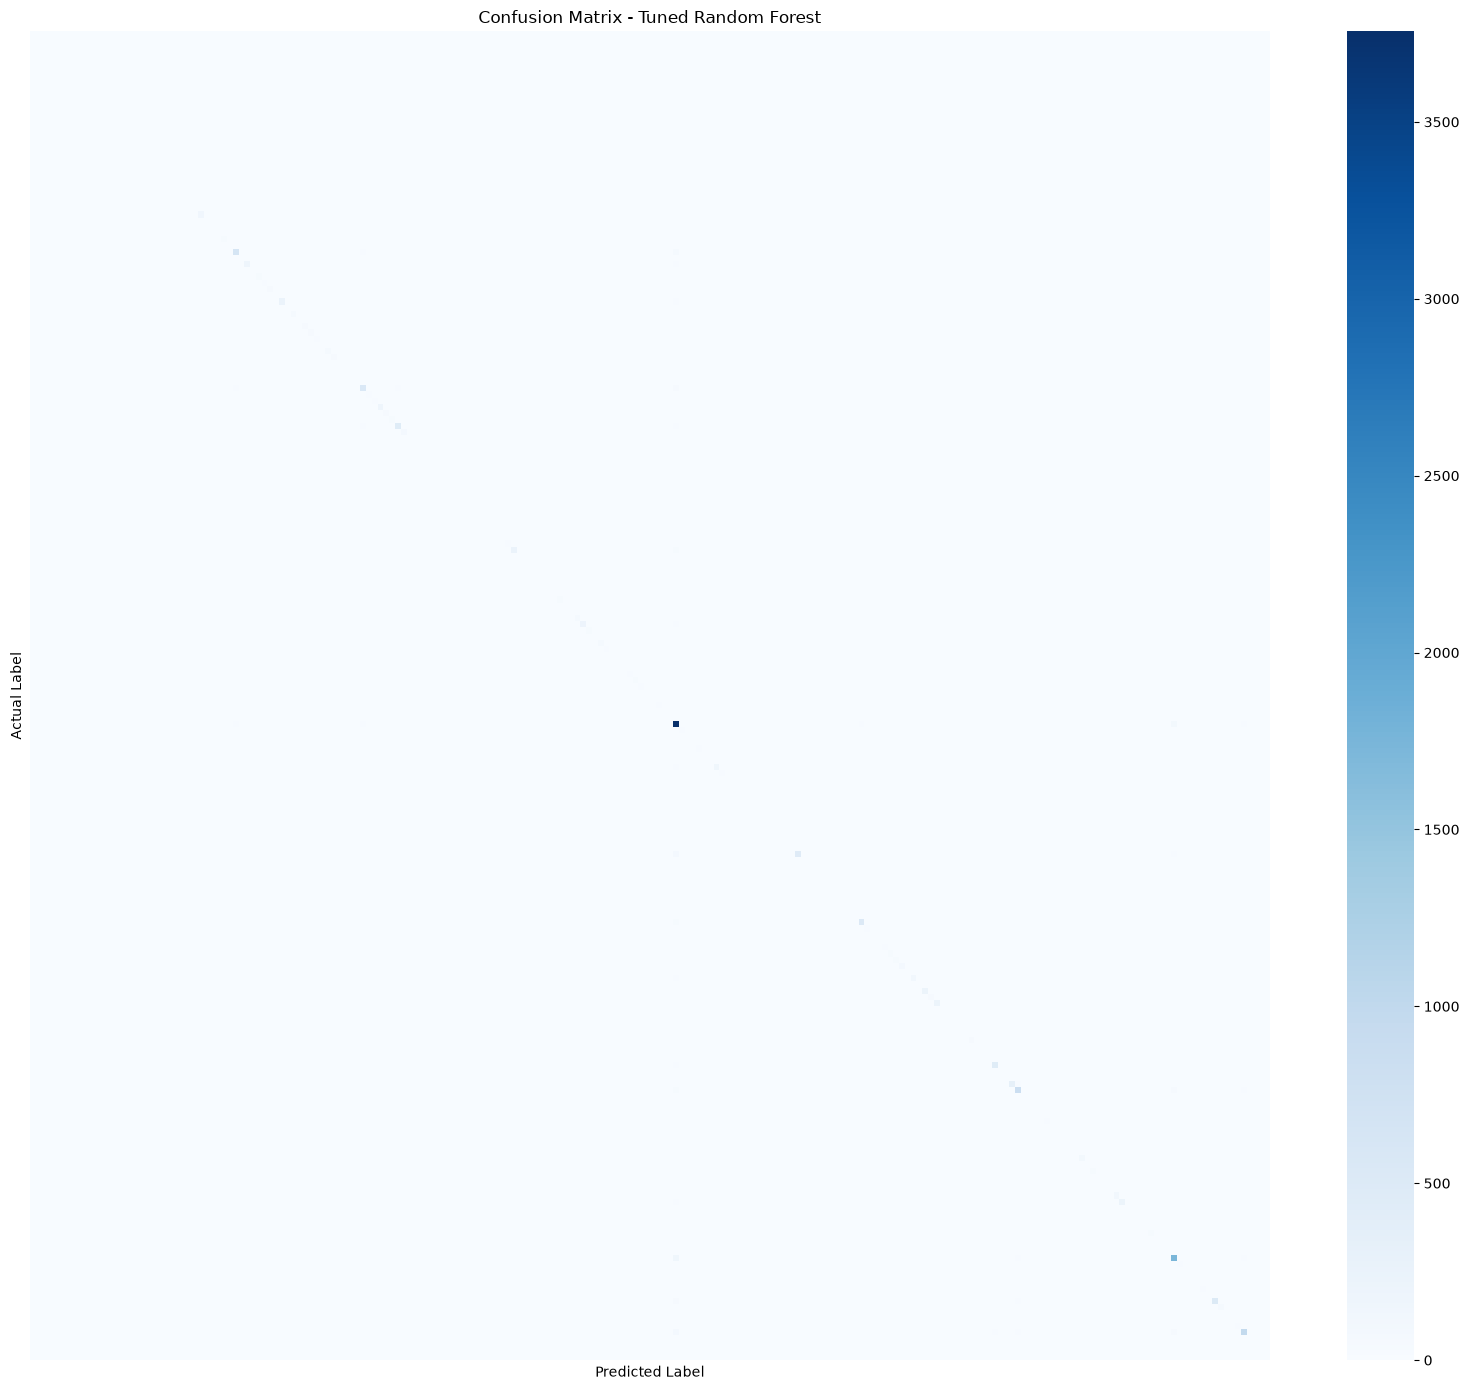

In [86]:
import os

os.makedirs("../outputs/figures", exist_ok=True)

plt.figure(figsize=(16, 14))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=False,
    yticklabels=False
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Tuned Random Forest")

plt.tight_layout()

plt.savefig(
    "../outputs/figures/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()